# P2.4 · Imbalanced binary classification (1 % positives)

**ID:** P2.4 · **Target:** 25 min · **Plan week:** 2 (timed repeat in week 4) · **Part:** P (PyTorch first principles)

**The drill.** About 1 % of examples are positive. Train the same MLP three ways (plain BCE, BCE with `pos_weight`,
and plain BCE with a class-balanced `WeightedRandomSampler`), evaluate them with metrics that are honest under
imbalance, and tune the decision threshold on val. Write the metrics by hand and check them against scikit-learn.

**Must include (from the plan):** `pos_weight` or sampler (here: both), precision/recall/F1, ROC-AUC vs PR-AUC,
threshold tuning. Also: the majority-class baseline, to show why accuracy misleads; initial-loss check (and
prior-bias init); overfit-one-batch; whole-set eval under `eval()` + `no_grad()`; test touched once.

**Rules.** No docs, no LLM. Each solution cell keeps only its spec. The self-check names the variables it expects.

## Sources
- T. Saito, M. Rehmsmeier, *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary
  Classifiers on Imbalanced Datasets*, PLOS ONE 10(3): e0118432, 2015, DOI 10.1371/journal.pone.0118432 —
  https://doi.org/10.1371/journal.pone.0118432
- J. Davis, M. Goadrich, *The Relationship Between Precision-Recall and ROC Curves*, ICML 2006, pp. 233-240,
  DOI 10.1145/1143844.1143874 — https://doi.org/10.1145/1143844.1143874 (a curve dominates in ROC space iff it
  dominates in PR space; linear interpolation between PR points is wrong).
- Z. C. Lipton, C. Elkan, B. Narayanaswamy, *Thresholding Classifiers to Maximize F1 Score*, ECML-PKDD 2014,
  arXiv:1402.1892 — https://arxiv.org/abs/1402.1892 (the F1-optimal threshold of a calibrated classifier is
  half the optimal F1, so it is far below 0.5 when positives are rare).
- scikit-learn `average_precision_score` (step-wise AP = Σ (Rₙ − Rₙ₋₁) Pₙ, no interpolation), `roc_auc_score`,
  `precision_recall_fscore_support`: https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-and-f-measures
- `torch.nn.BCEWithLogitsLoss` (`pos_weight`) and `torch.utils.data.WeightedRandomSampler` docs:
  https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html ·
  https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.WeightedRandomSampler
- A. Karpathy, *A Recipe for Training Neural Networks* (2019), "init well" (set the final bias to the class
  prior on imbalanced data): https://karpathy.github.io/2019/04/25/recipe/
- J. A. Hanley, B. J. McNeil, *The meaning and use of the area under a ROC curve*, Radiology 143(1):29-36, 1982,
  DOI 10.1148/radiology.143.1.7063747 — https://doi.org/10.1148/radiology.143.1.7063747 (AUC = P(score⁺ > score⁻)).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

from prep import Session, check, check_close, seed_everything

s = Session("P2.4", target_min=25)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[P2.4] started 16:42; target 25 min


In [2]:
# 1. DATA. sklearn make_classification(n_samples=60000, n_features=20, n_informative=4, n_redundant=4,
#    weights=[0.99], flip_y=0.0, class_sep=0.7, random_state=0). Print the prevalence.
#    STRATIFIED split 60/20/20 (train_test_split(..., stratify=y, random_state=0) twice). Standardize with train
#    stats. Tensors: X_* float32 (N, 20), y_* float32 (N,) (BCE wants float targets). Also keep numpy y_*_np.
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=60000, n_features=20, n_informative=4, n_redundant=4,
                           weights=[0.99], flip_y=0.0, class_sep=0.7, random_state=0)
print(X.shape, f"prevalence {y.mean():.4f} ({y.sum()} positives)")
X_train, X_tmp, y_train_np, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
X_val, X_test, y_val_np, y_test_np = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=0)
mu, sd = X_train.mean(0), X_train.std(0)
X_train, X_val, X_test = (torch.tensor((a - mu) / sd, dtype=torch.float32) for a in (X_train, X_val, X_test))
y_train, y_val, y_test = (torch.tensor(a, dtype=torch.float32) for a in (y_train_np, y_val_np, y_test_np))
print("positives per split:", int(y_train.sum()), int(y_val.sum()), int(y_test.sum()))

(60000, 20) prevalence 0.0100 (600 positives)
positives per split: 360 120 120


In [3]:
# 2. METRICS BY HAND (numpy in, python floats out; y in {0,1}).
#    prf(y, yhat) -> (precision, recall, f1); define 0/0 := 0 (sklearn's zero_division=0).
#    roc_auc(y, score): probability that a random positive scores higher than a random negative, ties count 1/2
#      (compare all positive-negative pairs with broadcasting; it's exact, including ties).
#    average_precision(y, score): sort by score descending; AP = mean over positives of precision@(rank of that
#      positive). (Equals sklearn's step-wise AP when scores have no ties.)
def prf(y, yhat):
    y, yhat = np.asarray(y).astype(bool), np.asarray(yhat).astype(bool)
    tp, fp, fn = np.sum(y & yhat), np.sum(~y & yhat), np.sum(y & ~yhat)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return float(p), float(r), float(f)


def roc_auc(y, score):
    y, score = np.asarray(y).astype(bool), np.asarray(score, dtype=np.float64)
    pos, neg = score[y], score[~y]
    diff = pos[:, None] - neg[None, :]  # (P, N) pairwise
    return float(((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size)


def average_precision(y, score):
    y = np.asarray(y).astype(bool)
    order = np.argsort(-np.asarray(score, dtype=np.float64), kind="stable")
    hits = y[order]
    prec_at_k = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return float(prec_at_k[hits].sum() / hits.sum())

In [4]:
# 3. WHY ACCURACY MISLEADS. Majority-class baseline on val: predict 0 for everyone, score = 0 constant.
#    `baseline = {"acc", "precision", "recall", "f1", "roc_auc", "ap"}` using your functions. Print it.
#    Note what AP equals for a constant (uninformative) score.
zeros = np.zeros_like(y_val_np, dtype=np.float64)
baseline = dict(zip(["precision", "recall", "f1"], prf(y_val_np, zeros)))
baseline.update(acc=float((zeros == y_val_np).mean()), roc_auc=roc_auc(y_val_np, zeros), ap=average_precision(y_val_np, zeros))
print({k: round(v, 4) for k, v in baseline.items()}, " prevalence", round(y_val_np.mean(), 4))

{'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'acc': 0.99, 'roc_auc': 0.5, 'ap': 0.0096}  prevalence 0.01


In [5]:
# 4. MODEL + DATA PIPELINES.
#    `MLP`: 20 -> 64 -> 64 -> 1, ReLU, returns (B,) logits. make_model(prior_bias=False): if True, set the last
#    layer's bias to log(p / (1 - p)) with p = train prevalence ("init well").
#    plain_dl: train, batch 256, shuffle=True.
#    sampler_dl: same data, batch 256, WeightedRandomSampler with per-EXAMPLE weight 1 / count(class of example),
#      num_samples = len(train), replacement=True (each batch then has ~50 % positives).
#    `pos_weight` = tensor(n_neg / n_pos) for BCEWithLogitsLoss.
class MLP(nn.Module):
    def __init__(self, d_in=20, d_h=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_h), nn.ReLU(), nn.Linear(d_h, d_h), nn.ReLU(), nn.Linear(d_h, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


prev = y_train.mean().item()


def make_model(prior_bias=False):
    m = MLP()
    if prior_bias:
        with torch.no_grad():
            m.net[-1].bias.fill_(math.log(prev / (1 - prev)))
    return m.to(dev)


train_ds = TensorDataset(X_train, y_train)
plain_dl = DataLoader(train_ds, batch_size=256, shuffle=True)
counts = torch.bincount(y_train.long())
ex_w = (1.0 / counts.double())[y_train.long()]
sampler = WeightedRandomSampler(ex_w, num_samples=len(train_ds), replacement=True)
sampler_dl = DataLoader(train_ds, batch_size=256, sampler=sampler)
pos_weight = torch.tensor(counts[0].item() / counts[1].item(), dtype=torch.float32)
print(f"pos_weight = {pos_weight.item():.1f}; positives in one sampled batch: {next(iter(sampler_dl))[1].mean():.2f}")

pos_weight = 99.0; positives in one sampled batch: 0.45


In [6]:
# 5. SANITY CHECKS. On the val set, BCE of a fresh model:
#    `init_loss_default` (default init, expect ≈ ln 2) and `init_loss_prior` (prior-bias init, expect ≈ the binary
#    entropy H(p) = -p ln p - (1-p) ln(1-p)). Then overfit ONE sampler batch (256, ~half positives) with a fresh
#    model, Adam lr=1e-2, 300 steps -> `overfit_loss` (< 0.05).
bce = nn.BCEWithLogitsLoss()
with torch.no_grad():
    init_loss_default = bce(make_model()(X_val.to(dev)), y_val.to(dev)).item()
    init_loss_prior = bce(make_model(prior_bias=True)(X_val.to(dev)), y_val.to(dev)).item()
H = -prev * math.log(prev) - (1 - prev) * math.log(1 - prev)
print(f"init BCE default {init_loss_default:.3f} (ln2 {math.log(2):.3f}); prior-bias {init_loss_prior:.4f} (H(p) {H:.4f})")
xb, yb = next(iter(sampler_dl))
xb, yb = xb.to(dev), yb.to(dev)
tmp = make_model()
tmp_opt = torch.optim.Adam(tmp.parameters(), lr=1e-2)
for _ in range(300):
    loss = bce(tmp(xb), yb)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_loss = loss.item()
print(f"overfit-one-batch loss {overfit_loss:.4f}")

init BCE default 0.747 (ln2 0.693); prior-bias 0.0559 (H(p) 0.0560)


overfit-one-batch loss 0.0000


In [7]:
# 6. TRAIN THREE WAYS. `train(mode, epochs=15) -> model`, with torch.manual_seed(0) at the start, AdamW lr=1e-3:
#      "plain":      plain_dl,   BCEWithLogitsLoss(),                      prior-bias init
#      "pos_weight": plain_dl,   BCEWithLogitsLoss(pos_weight=pos_weight), default init
#      "sampler":    sampler_dl, BCEWithLogitsLoss(),                      default init
#    `scores(model, X) -> numpy probabilities` (eval, no_grad, sigmoid). models = {mode: model}.
#    val_probs = {mode: probabilities on val}.
def train(mode, epochs=15):
    torch.manual_seed(0)
    model = make_model(prior_bias=(mode == "plain"))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(dev) if mode == "pos_weight" else None)
    dl = sampler_dl if mode == "sampler" else plain_dl
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model


@torch.no_grad()
def scores(model, X):
    model.eval()
    return torch.sigmoid(model(X.to(dev))).double().cpu().numpy()


models = {m: train(m) for m in ("plain", "pos_weight", "sampler")}
val_probs = {m: scores(models[m], X_val) for m in models}

In [8]:
# 7. COMPARE AT THRESHOLD 0.5 (val). For each model: accuracy, precision, recall, F1 at p >= 0.5, ROC-AUC, AP.
#    Store `val_at_05 = {mode: {"acc", "precision", "recall", "f1", "roc_auc", "ap"}}`; print a table
#    (include the majority baseline row). What do the ranking metrics (AUC, AP) say vs the thresholded ones?
def report(y, p, t):
    pr, rc, f1 = prf(y, p >= t)
    return {"acc": float(((p >= t) == y).mean()), "precision": pr, "recall": rc, "f1": f1,
            "roc_auc": roc_auc(y, p), "ap": average_precision(y, p)}


val_at_05 = {m: report(y_val_np, val_probs[m], 0.5) for m in models}
print(f"{'model':11s} " + " ".join(f"{k:>9s}" for k in baseline))
for name, r in [("majority", baseline)] + list(val_at_05.items()):
    print(f"{name:11s} " + " ".join(f"{r[k]:9.4f}" for k in baseline))

model       precision    recall        f1       acc   roc_auc        ap
majority       0.0000    0.0000    0.0000    0.9900    0.5000    0.0096
plain          0.8235    0.3500    0.4912    0.9928    0.9733    0.5342
pos_weight     0.1245    0.7750    0.2145    0.9433    0.9634    0.4135
sampler        0.2630    0.5917    0.3641    0.9793    0.9714    0.4852


In [9]:
# 8. THRESHOLD TUNING ON VAL. best_threshold(y, p) -> (t, f1): the threshold maximizing F1 of (p >= t), searching
#    over all distinct scores. Vectorize: sort p descending, cumulative TP/FP at each cut, F1 = 2TP / (2TP + FP + FN);
#    with tied scores only the LAST index of each tie group is a valid cut.
#    `thresholds = {mode: t}` from val; then (test touched once) `test_tuned = {mode: report(y_test, p_test, t)}`
#    and `test_at_05` likewise at 0.5. Print both tables.
def best_threshold(y, p):
    y, p = np.asarray(y).astype(bool), np.asarray(p, dtype=np.float64)
    order = np.argsort(-p, kind="stable")
    ps, ys = p[order], y[order]
    tp = np.cumsum(ys)
    fp = np.cumsum(~ys)
    fn = ys.sum() - tp
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    valid = np.r_[ps[1:] != ps[:-1], True]  # last element of each tie group
    i = np.flatnonzero(valid)[np.argmax(f1[valid])]
    return float(ps[i]), float(f1[i])


thresholds = {m: best_threshold(y_val_np, val_probs[m])[0] for m in models}
test_probs = {m: scores(models[m], X_test) for m in models}
test_at_05 = {m: report(y_test_np, test_probs[m], 0.5) for m in models}
test_tuned = {m: report(y_test_np, test_probs[m], thresholds[m]) for m in models}
for title, tab in [("TEST @ 0.5", test_at_05), ("TEST @ val-tuned threshold", test_tuned)]:
    print(title)
    for m, r in tab.items():
        extra = f"  t={thresholds[m]:.3f}" if tab is test_tuned else ""
        print(f"  {m:11s} P {r['precision']:.3f} R {r['recall']:.3f} F1 {r['f1']:.3f} AUC {r['roc_auc']:.4f} AP {r['ap']:.4f}{extra}")

TEST @ 0.5
  plain       P 0.815 R 0.367 F1 0.506 AUC 0.9713 AP 0.5442
  pos_weight  P 0.127 R 0.817 F1 0.220 AUC 0.9614 AP 0.3982
  sampler     P 0.262 R 0.558 F1 0.356 AUC 0.9651 AP 0.4822
TEST @ val-tuned threshold
  plain       P 0.611 R 0.458 F1 0.524 AUC 0.9713 AP 0.5442  t=0.274
  pos_weight  P 0.667 R 0.267 F1 0.381 AUC 0.9614 AP 0.3982  t=0.991
  sampler     P 0.409 R 0.467 F1 0.436 AUC 0.9651 AP 0.4822  t=0.888


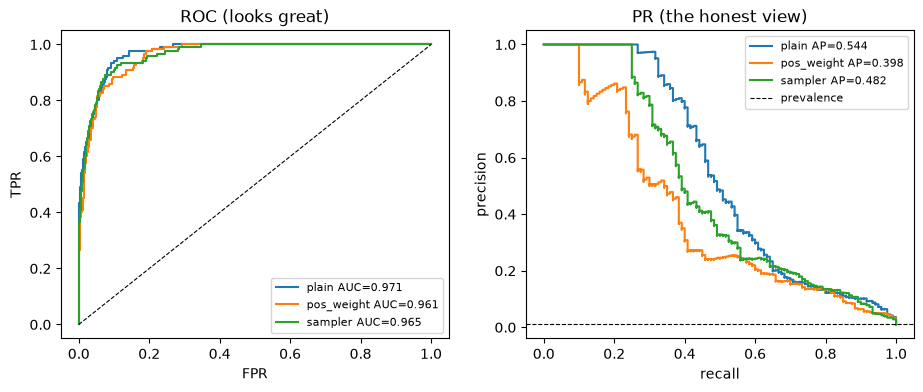

In [10]:
# 9. CURVES (test). Left: ROC curves of the three models + the chance diagonal. Right: PR curves + a horizontal
#    line at the prevalence (the PR chance level). You may use sklearn.metrics.roc_curve / precision_recall_curve
#    for plotting only.
from sklearn.metrics import precision_recall_curve, roc_curve

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in models:
    fpr, tpr, _ = roc_curve(y_test_np, test_probs[m])
    pr, rc, _ = precision_recall_curve(y_test_np, test_probs[m])
    ax[0].plot(fpr, tpr, label=f"{m} AUC={test_tuned[m]['roc_auc']:.3f}")
    ax[1].plot(rc, pr, drawstyle="steps-post", label=f"{m} AP={test_tuned[m]['ap']:.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].axhline(y_test_np.mean(), c="k", ls="--", lw=0.8, label="prevalence")
ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC (looks great)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="recall", ylabel="precision", title="PR (the honest view)"); ax[1].legend(fontsize=8)
plt.show()

## Self-check
Expects: `y_train`, `prf`, `roc_auc`, `average_precision`, `baseline`, `pos_weight`, `sampler_dl`,
`init_loss_default`, `init_loss_prior`, `overfit_loss`, `models`, `val_probs`, `val_at_05`, `best_threshold`,
`thresholds`, `test_tuned`.

In [11]:
from sklearn.metrics import average_precision_score, f1_score, precision_recall_fscore_support, roc_auc_score

rng = np.random.default_rng(0)
yy = (rng.random(2000) < 0.05).astype(int)
ss = rng.random(2000) + 0.6 * yy                 # continuous scores, informative
hard = (ss > 0.9).astype(int)
check("targets are float for BCE", y_train.dtype == torch.float32)
check_close("prf == sklearn", prf(yy, hard), precision_recall_fscore_support(yy, hard, average="binary", zero_division=0)[:3])
check_close("prf zero division -> 0", prf(yy, np.zeros_like(yy)), [0.0, 0.0, 0.0])
check_close("roc_auc == sklearn", roc_auc(yy, ss), roc_auc_score(yy, ss))
check_close("roc_auc with ties == sklearn", roc_auc(yy, np.round(ss, 1)), roc_auc_score(yy, np.round(ss, 1)))
check_close("average_precision == sklearn", average_precision(yy, ss), average_precision_score(yy, ss))
check("majority baseline: high accuracy, zero F1", baseline["acc"] > 0.98 and baseline["f1"] == 0.0, str(baseline))
check_close("constant score: AUC = 0.5", baseline["roc_auc"], 0.5)
check_close("pos_weight = n_neg / n_pos", float(pos_weight), float((y_train == 0).sum() / (y_train == 1).sum()), rtol=1e-3)
frac = torch.cat([yb for _, yb in sampler_dl]).mean().item()
check("sampler balances classes (~50 % positives per epoch)", 0.4 < frac < 0.6, f"got {frac:.3f}")
check("initial loss default init ~ ln 2", abs(init_loss_default - math.log(2)) < 0.15, f"got {init_loss_default:.3f}")
p0 = y_train.mean().item()
check("initial loss with prior bias ~ H(p)", abs(init_loss_prior - (-p0 * math.log(p0) - (1 - p0) * math.log(1 - p0))) < 0.02, f"got {init_loss_prior:.4f}")
check("can overfit one batch", overfit_loss < 0.05, f"got {overfit_loss:.4f}")
for m in models:
    t, f = best_threshold(y_val_np, val_probs[m])
    cand = np.unique(np.r_[val_probs[m], 0.5])
    brute = max(f1_score(y_val_np, val_probs[m] >= c) for c in cand[::max(1, len(cand) // 400)])
    check(f"{m}: tuned val F1 == sklearn F1 at t", abs(f - f1_score(y_val_np, val_probs[m] >= t)) < 1e-9)
    check(f"{m}: tuned F1 >= F1 at 0.5 and >= sub-sampled brute force", f >= val_at_05[m]["f1"] - 1e-9 and f >= brute - 1e-9)
    check(f"{m}: ROC-AUC > 0.90 on test", test_tuned[m]["roc_auc"] > 0.90, f"got {test_tuned[m]['roc_auc']:.3f}")
    check(f"{m}: AP well above prevalence on test", test_tuned[m]["ap"] > 10 * y_test_np.mean(), f"got {test_tuned[m]['ap']:.3f}")
check("pos_weight model needs a higher threshold than the plain model",
      thresholds["pos_weight"] > thresholds["plain"], f"{thresholds}")

ok  targets are float for BCE
ok  prf == sklearn
ok  prf zero division -> 0
ok  roc_auc == sklearn
ok  roc_auc with ties == sklearn
ok  average_precision == sklearn
ok  majority baseline: high accuracy, zero F1
ok  constant score: AUC = 0.5
ok  pos_weight = n_neg / n_pos
ok  sampler balances classes (~50 % positives per epoch)
ok  initial loss default init ~ ln 2
ok  initial loss with prior bias ~ H(p)
ok  can overfit one batch


ok  plain: tuned val F1 == sklearn F1 at t
ok  plain: tuned F1 >= F1 at 0.5 and >= sub-sampled brute force
ok  plain: ROC-AUC > 0.90 on test
ok  plain: AP well above prevalence on test


ok  pos_weight: tuned val F1 == sklearn F1 at t
ok  pos_weight: tuned F1 >= F1 at 0.5 and >= sub-sampled brute force
ok  pos_weight: ROC-AUC > 0.90 on test
ok  pos_weight: AP well above prevalence on test


ok  sampler: tuned val F1 == sklearn F1 at t
ok  sampler: tuned F1 >= F1 at 0.5 and >= sub-sampled brute force
ok  sampler: ROC-AUC > 0.90 on test
ok  sampler: AP well above prevalence on test
ok  pos_weight model needs a higher threshold than the plain model


## Say it out loud (P3)
1. The majority baseline has ~99 % accuracy. Why is accuracy the wrong headline metric here, and what would you report?
2. ROC-AUC barely separates the three models; AP/PR curves separate them more. Why (what does FPR hide when negatives are 99 %)?
3. What does `pos_weight = n_neg/n_pos` do to the loss and gradients? What does it do to the *calibration* of the probabilities?
4. Sampler vs `pos_weight`: same expected gradient? What are the practical differences (variance, epochs, overfitting)?
5. Why is the F1-optimal threshold of the plain model far below 0.5, and why must it be tuned on val, not test?
6. What is the chance level of AP, and why isn't it 0.5? Why shouldn't you linearly interpolate a PR curve?
7. Why set the final bias to log(p/(1−p)) at init? What does the initial loss become?

<details><summary>Model answers</summary>

1. Predicting "negative" for everyone gets accuracy 1 − prevalence ≈ 0.99 with zero recall. Report the precision
   and recall (or F1) at the operating threshold you would deploy, PR-AUC/AP as the threshold-free summary, and
   the prevalence next to them so readers know the chance level. If costs are known, report the expected cost.
2. FPR = FP/(FP+TN). With about 11 900 negatives, even hundreds of false positives are a small FPR, so ROC curves
   of models with very different precision look similar and all reach AUC ≈ 0.96-0.97. Precision = TP/(TP+FP) puts the
   FP count directly against the few positives, so PR curves and AP expose the difference. This is the point of
   Saito & Rehmsmeier (2015). Davis & Goadrich (2006) show that a curve dominates in ROC space iff it dominates in
   PR space, but the areas can rank non-dominating curves differently.
3. It multiplies the positive term of the BCE by w, so positives count w times and their gradients
   (σ(z) − 1)·w are scaled by w. The minimiser shifts to σ(z*) = w·p/(w·p + 1 − p) instead of p: the logits move
   up by log w, and the probabilities are no longer calibrated (they over-predict positives). That is why the
   tuned threshold is high for this model. Use a threshold, recalibrate (Platt/isotonic on val), or subtract log w
   from the logit if you need true probabilities.
4. In expectation both reweight the positive class. The sampler does it by repeating positives (with
   replacement), so an "epoch" sees each positive about 50 times. Gradients have lower variance per batch (every
   batch has positives), but the model memorises the same few hundred positives faster and can overfit.
   `pos_weight` keeps every negative and has noisier batches (about 2 positives per batch of 256 here).
   Neither changes the ranking much, which is why AUC/AP stay close. In this run the plain model with a tuned
   threshold had the best test F1 and AP. Reweighting mostly moved the threshold (to about 0.9-0.99) and slightly
   hurt the ranking. Reweighting helps most when the model is capacity- or step-limited on the rare class.
5. For rare positives, a calibrated model rarely gets above 0.5, so p ≥ 0.5 gives low recall. Lipton et al. show
   that the F1-optimal threshold of a calibrated classifier is half the achievable F1. Here the plain model's tuned
   threshold is ≈ 0.27, close to half of its F1 ≈ 0.5.
   Tuning on test would make the reported F1 optimistically biased: the threshold is a hyperparameter.
6. A random scorer has precision ≈ prevalence at every recall, so AP ≈ prevalence (about 0.01 here), not 0.5.
   Precision does not vary linearly between PR points (Davis & Goadrich 2006), so trapezoidal interpolation
   over-estimates the area. sklearn's AP uses the step-wise sum Σ (Rₙ − Rₙ₋₁) Pₙ instead.
7. With bias = logit(p) the model starts out predicting the base rate. The initial loss is then the binary entropy
   H(p) ≈ 0.056 instead of ln 2 ≈ 0.693. Otherwise the first few hundred steps are spent learning the bias (a
   "hockey-stick" loss curve), and those early large gradients can destabilise training.
</details>

In [12]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.4] done in 0.4 min (within target 25 min)


0.44851793845494586